# 2.3–2.4 Chuẩn bị dữ liệu và baseline ResNet-18

Notebook này:
1. Đọc metadata + ánh xạ đường dẫn ảnh
2. **Kiểm tra & tiền xử lý dữ liệu dạng bảng** (không xử lý ảnh): giá trị thiếu, trùng lặp, tính nhất quán, outlier, phân bố nhãn
3. Mã hoá nhãn, chia **train / val / test theo `lesion_id`**
4. **Xử lý mất cân bằng lớp bằng Weighted Random Sampling** (`WeightedRandomSampler`)
5. Huấn luyện **baseline ResNet-18** (chỉ resize + normalize, không xử lý ảnh chương 3) với **3 seed** và ghi lại điểm

Code train/đánh giá nằm trong module dùng chung **`src/training.py`** (`run_experiment`). Mọi thí nghiệm tiền xử lý
sau này gọi đúng hàm này, chỉ khác tham số `preprocess_fn` → bảo đảm ablation chỉ thay đổi một yếu tố.

Mọi kết quả lưu ở `outputs/baseline/` (số liệu) và `outputs/figures/baseline/` (hình).

## 1. Import & cấu hình

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold

import torch
from torch.utils.data import WeightedRandomSampler

from src.eda.plots import CLASS_COLORS, setup_style   # cùng màu/thứ tự lớp với EDA
from src import training as T                          # code train/đánh giá dùng chung cho mọi thí nghiệm
from src.training import run_experiment, seed_everything, load_results

SEED = 42
DATA_DIR = Path("archive")
METADATA_CSV = DATA_DIR / "HAM10000_metadata.csv"
IMAGE_DIRS = [DATA_DIR / "HAM10000_images_part_1", DATA_DIR / "HAM10000_images_part_2"]
SPLIT_DIR = Path("outputs/splits")
PREP_DIR = Path("outputs/data_prep")
OUT_DIR = Path("outputs/baseline")
FIG_DIR = Path("outputs/figures/baseline")
for d in (SPLIT_DIR, PREP_DIR, OUT_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

TEST_SIZE = 0.2      # ~20% test (đã cố định trong outputs/splits/test.csv)
VAL_SIZE = 0.2       # ~20% của train -> validation (chọn epoch, không dùng test)
IMG_SIZE = T.IMG_SIZE
BATCH_SIZE = T.BATCH_SIZE

seed_everything(SEED)
setup_style()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch:", torch.__version__, "| device:", device,
      "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "")

torch: 2.13.0+cu126 | device: cuda | NVIDIA L40S


## 2. Đọc dữ liệu

In [2]:
df = pd.read_csv(METADATA_CSV)
print(df.shape)
df.head()

(10015, 7)


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10015 entries, 0 to 10014
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   lesion_id     10015 non-null  str    
 1   image_id      10015 non-null  str    
 2   dx            10015 non-null  str    
 3   dx_type       10015 non-null  str    
 4   age           9958 non-null   float64
 5   sex           10015 non-null  str    
 6   localization  10015 non-null  str    
dtypes: float64(1), str(6)
memory usage: 990.6 KB


In [4]:
# Ánh xạ image_id -> đường dẫn file (ảnh nằm rải ở 2 thư mục)
image_paths = {p.stem: p for d in IMAGE_DIRS for p in d.glob("*.jpg")}
df["path"] = df["image_id"].map(image_paths)
print("Số file ảnh tìm thấy:", len(image_paths))

Số file ảnh tìm thấy: 10015


## 3. Kiểm tra & tiền xử lý dữ liệu dạng bảng

Phần này **chỉ xử lý các vấn đề về số liệu/metadata**, không đụng tới pixel ảnh. Tóm tắt cách làm cho từng vấn đề
(số liệu cụ thể xem output các ô bên dưới):

| Vấn đề | Cách kiểm tra | Cách xử lý đang dùng | Lý do |
|---|---|---|---|
| Giá trị thiếu (`age` NaN, `sex`/`localization` = `unknown`) | Đếm NaN + chuỗi `unknown`, xem phân bố theo `dx` | **Giữ toàn bộ dòng.** `age`: điền **median của tập train** + cột cờ `age_missing`. `sex`/`localization`: giữ `unknown` như một nhóm riêng | Mô hình chỉ dùng ảnh + `dx`; ảnh và nhãn của các dòng này đầy đủ → xoá dòng chỉ làm mất ảnh. Median fit trên train để không rò rỉ |
| Thiếu nhãn / thiếu file ảnh | `dx` NaN, `image_id` không có file | Dừng (assert) nếu có | Không có nhãn/ảnh thì không thể dùng |
| Trùng lặp | Dòng trùng, `image_id` trùng, file thừa; cặp ảnh gần trùng (từ EDA) | Không xoá; **chia theo `lesion_id`** | Ảnh gần trùng đều cùng `lesion_id` → nhóm theo lesion đã ngăn rò rỉ train/test |
| Nhất quán | 1 lesion ↔ 1 `dx`; metadata trong cùng lesion; kích thước/mode **toàn bộ** ảnh | Báo cáo; dừng nếu 1 lesion có nhiều `dx` | Nhãn mâu thuẫn trong một lesion sẽ là nhiễu nhãn |
| Outlier | Quy tắc IQR (1.5×IQR) cho `age`; số ảnh/lesion | **Gắn cờ, không xoá** (`age_outlier`) | Tuổi thấp vẫn hợp lý về mặt y khoa và không phải đầu vào mô hình; xoá sẽ mất ảnh hợp lệ |
| Mất cân bằng lớp | Tỉ lệ lớn nhất/nhỏ nhất | **Weighted Random Sampling** (mục 6) | Theo chỉ định; chi tiết ở mục 6 |

### 3.1 Giá trị thiếu (NaN và giá trị `unknown`)

In [5]:
missing = pd.DataFrame({
    "nan": df.isna().sum(),
    "unknown": (df.astype(str).apply(lambda s: s.str.lower()) == "unknown").sum(),
})
missing["tổng"] = missing.sum(axis=1)
missing["%"] = (missing["tổng"] / len(df) * 100).round(2)
missing

,nan,unknown,tổng,%
lesion_id,0,0,0,0.00
image_id,0,0,0,0.00
dx,0,0,0,0.00
dx_type,0,0,0,0.00
age,57,0,57,0.57
sex,0,57,57,0.57
localization,0,234,234,2.34
path,0,0,0,0.00


In [6]:
# Giá trị thiếu tập trung ở lớp nào? (nếu chỉ ở 1-2 lớp thì xoá dòng sẽ làm lệch phân bố nhãn)
miss_by_dx = pd.DataFrame({
    "age NaN": df[df["age"].isna()]["dx"].value_counts(),
    "sex unknown": df[df["sex"] == "unknown"]["dx"].value_counts(),
    "localization unknown": df[df["localization"] == "unknown"]["dx"].value_counts(),
    "tổng ảnh": df["dx"].value_counts(),
}).fillna(0).astype(int)
print("Số dòng thiếu ≥1 trường metadata:",
      (df["age"].isna() | (df["sex"] == "unknown") | (df["localization"] == "unknown")).sum())
miss_by_dx

Số dòng thiếu ≥1 trường metadata: 254


,age NaN,sex unknown,localization unknown,tổng ảnh
dx,,,,
akiec,0,0,0,327
bcc,0,0,5,514
bkl,10,10,23,1099
df,0,0,0,115
mel,2,0,10,1113
nv,45,47,196,6705
vasc,0,0,0,142


> Giá trị thiếu chỉ nằm ở **metadata phụ** (`age`, `sex`, `localization`), không nằm ở ảnh hay nhãn `dx`.
> Xoá các dòng này sẽ bỏ ảnh hợp lệ và lấy bớt ảnh không đều giữa các lớp (xem bảng trên), nên **giữ lại tất cả dòng**.
> `age` sẽ được điền bằng median **tính trên tập train** sau khi chia (mục 5.3) và kèm cờ `age_missing`;
> `sex`/`localization` giữ `unknown` làm một nhóm riêng (điền mode sẽ tạo thông tin giả).

In [7]:
assert df["dx"].isna().sum() == 0, "Có ảnh thiếu nhãn!"
assert df["path"].isna().sum() == 0, "Có image_id không tìm thấy file ảnh!"
df["age_missing"] = df["age"].isna()
print("Không thiếu nhãn, mọi image_id đều có file ảnh.")

Không thiếu nhãn, mọi image_id đều có file ảnh.


### 3.2 Trùng lặp

In [8]:
print("Dòng trùng hoàn toàn       :", df.drop(columns="path").duplicated().sum())
print("image_id trùng             :", df["image_id"].duplicated().sum())
orphans = set(image_paths) - set(df["image_id"])
print("File ảnh không có metadata :", len(orphans))

# Mỗi lesion_id có thể có nhiều ảnh -> phải chia theo nhóm
imgs_per_lesion = df.groupby("lesion_id").size()
print("Số lesion_id               :", df["lesion_id"].nunique())
print("Số ảnh / lesion            :", imgs_per_lesion.value_counts().sort_index().to_dict())

# Ảnh gần trùng (tính trong EDA, 2.2_eda_chat_luong_anh.ipynb): có cặp nào khác lesion không?
nd_path = Path("outputs/eda/near_duplicates.csv")
if nd_path.exists():
    nd = pd.read_csv(nd_path)
    print(f"Cặp ảnh gần trùng (EDA)    : {len(nd)} | khác lesion_id: {(~nd['same_lesion']).sum()}")
else:
    print("Chưa có outputs/eda/near_duplicates.csv (chạy EDA trước) -> bỏ qua")

Dòng trùng hoàn toàn       : 0
image_id trùng             : 0
File ảnh không có metadata : 0
Số lesion_id               : 7470
Số ảnh / lesion            : {1: 5514, 2: 1423, 3: 490, 4: 34, 5: 5, 6: 4}
Chưa có outputs/eda/near_duplicates.csv (chạy EDA trước) -> bỏ qua


### 3.3 Tính nhất quán

In [9]:
# Mỗi lesion chỉ thuộc 1 nhãn? (nếu không -> nhiễu nhãn)
assert (df.groupby("lesion_id")["dx"].nunique() == 1).all(), "Có lesion mang nhiều nhãn!"
print("Mỗi lesion_id chỉ có 1 nhãn dx.")

# Metadata trong cùng lesion có khớp không?
incons = df.groupby("lesion_id")[["dx_type", "age", "sex", "localization"]].nunique(dropna=True).gt(1).sum()
print("Số lesion có metadata không nhất quán:", incons.to_dict())
bad = df.groupby("lesion_id")["localization"].nunique().loc[lambda s: s > 1].index
df[df["lesion_id"].isin(bad)][["lesion_id", "image_id", "dx", "localization"]]

Mỗi lesion_id chỉ có 1 nhãn dx.
Số lesion có metadata không nhất quán: {'dx_type': 0, 'age': 0, 'sex': 0, 'localization': 2}


,lesion_id,image_id,dx,localization
1211,HAM_0000871,ISIC_0025964,mel,chest
1212,HAM_0000871,ISIC_0030623,mel,chest
1247,HAM_0001726,ISIC_0029281,mel,back
1248,HAM_0001726,ISIC_0024367,mel,back
2008,HAM_0001726,ISIC_0024700,mel,trunk
2014,HAM_0000871,ISIC_0026506,mel,trunk


> Vài lesion có `localization` khác nhau giữa các ảnh. Đây chỉ là metadata phụ, không ảnh hưởng nhãn `dx` → giữ nguyên, ghi nhận.

In [10]:
# Kích thước / mode của TOÀN BỘ ảnh (Image.open chỉ đọc header -> nhanh)
def img_meta(p):
    with Image.open(p) as im:
        return im.size, im.mode
sizes = pd.Series([img_meta(p) for p in df["path"]])
print(sizes.value_counts())

((600, 450), RGB)    10015
Name: count, dtype: int64


### 3.4 Outlier

age: Q1=40.0, Q3=65.0, IQR=25.0 -> ngưỡng [2.5, 102.5]
Giá trị age khác nhau: [np.float64(0.0), np.float64(5.0), np.float64(10.0), np.float64(15.0), np.float64(20.0), np.float64(25.0), np.float64(30.0), np.float64(35.0), np.float64(40.0), np.float64(45.0), np.float64(50.0), np.float64(55.0), np.float64(60.0), np.float64(65.0), np.float64(70.0), np.float64(75.0), np.float64(80.0), np.float64(85.0)]
Số ảnh outlier theo age: 39 | giá trị: {0.0: 39}
Phân bố dx của outlier: {'nv': 30, 'bkl': 5, 'vasc': 4}


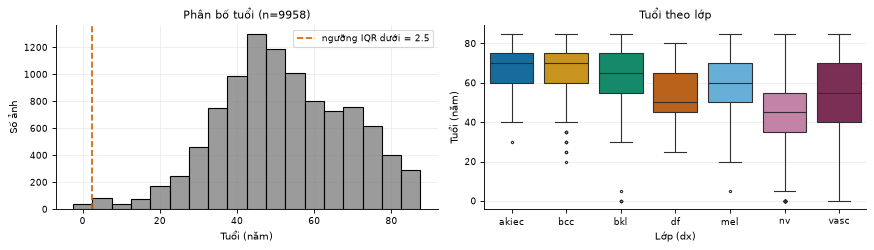

In [11]:
# Quy tắc IQR (Tukey): ngoài [Q1 - 1.5·IQR, Q3 + 1.5·IQR]
q1, q3 = df["age"].quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
df["age_outlier"] = (df["age"] < lo) | (df["age"] > hi)
print(f"age: Q1={q1}, Q3={q3}, IQR={iqr} -> ngưỡng [{lo}, {hi}]")
print("Giá trị age khác nhau:", sorted(df["age"].dropna().unique()))
print("Số ảnh outlier theo age:", df["age_outlier"].sum(),
      "| giá trị:", df.loc[df["age_outlier"], "age"].value_counts().to_dict())
print("Phân bố dx của outlier:", df.loc[df["age_outlier"], "dx"].value_counts().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
sns.histplot(df["age"], bins=np.arange(-2.5, 90, 5), ax=axes[0], color="#7A7A7A")
axes[0].axvline(lo, ls="--", c="#D55E00", label=f"ngưỡng IQR dưới = {lo}")
axes[0].set(xlabel="Tuổi (năm)", ylabel="Số ảnh", title=f"Phân bố tuổi (n={df['age'].notna().sum()})")
axes[0].legend()
order = sorted(df["dx"].unique())
sns.boxplot(data=df, x="dx", y="age", order=order, palette=CLASS_COLORS, hue="dx", legend=False, ax=axes[1], fliersize=2)
axes[1].set(xlabel="Lớp (dx)", ylabel="Tuổi (năm)", title="Tuổi theo lớp")
plt.tight_layout(); fig.savefig(FIG_DIR / "age_outlier.pdf", bbox_inches="tight"); plt.show()

> `age` được ghi theo bội số của 5 (đã làm tròn sẵn). Các giá trị bị quy tắc IQR đánh dấu là tuổi rất thấp — vẫn **hợp lý** (trẻ em
> có nốt ruồi/tổn thương mạch máu), không phải lỗi nhập liệu. Vì `age` không phải đầu vào mô hình và ảnh/nhãn của các dòng này
> hợp lệ, **chỉ gắn cờ `age_outlier`, không xoá**. Số ảnh/lesion (tối đa 6) cũng không phải outlier cần loại: được xử lý bằng chia theo `lesion_id`.

### 3.5 Phân bố nhãn

In [12]:
DX_NAMES = {
    "nv": "Melanocytic nevi",
    "mel": "Melanoma",
    "bkl": "Benign keratosis-like lesions",
    "bcc": "Basal cell carcinoma",
    "akiec": "Actinic keratoses / Bowen's",
    "vasc": "Vascular lesions",
    "df": "Dermatofibroma",
}
counts = df["dx"].value_counts()
print(f"Mất cân bằng: lớp lớn nhất / nhỏ nhất = {counts.max() / counts.min():.1f}x")
pd.DataFrame({"tên": counts.index.map(DX_NAMES), "số ảnh": counts,
              "%": (counts / len(df) * 100).round(2)})

Mất cân bằng: lớp lớn nhất / nhỏ nhất = 58.3x


,tên,số ảnh,%
dx,,,
nv,Melanocytic nevi,6705,66.95
mel,Melanoma,1113,11.11
bkl,Benign keratosis-like lesions,1099,10.97
bcc,Basal cell carcinoma,514,5.13
akiec,Actinic keratoses / Bowen's,327,3.27
vasc,Vascular lesions,142,1.42
df,Dermatofibroma,115,1.15


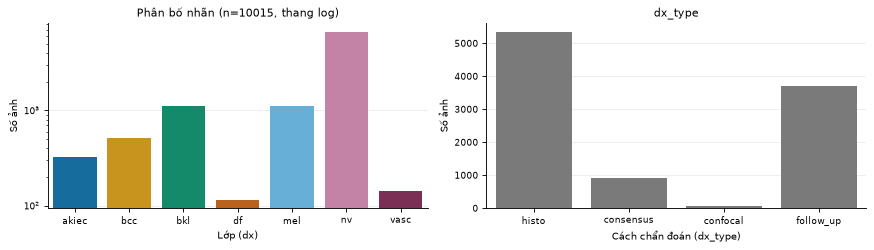

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
sns.countplot(data=df, x="dx", order=sorted(df["dx"].unique()), hue="dx", palette=CLASS_COLORS, legend=False, ax=axes[0])
axes[0].set(xlabel="Lớp (dx)", ylabel="Số ảnh", yscale="log", title=f"Phân bố nhãn (n={len(df)}, thang log)")
sns.countplot(data=df, x="dx_type", ax=axes[1], color="#7A7A7A")
axes[1].set(xlabel="Cách chẩn đoán (dx_type)", ylabel="Số ảnh", title="dx_type")
plt.tight_layout(); fig.savefig(FIG_DIR / "class_distribution.pdf", bbox_inches="tight"); fig.savefig(FIG_DIR / "class_distribution.png", bbox_inches="tight", dpi=300); plt.show()

## 4. Mã hoá nhãn

In [14]:
CLASSES = sorted(df["dx"].unique())
class_to_idx = {c: i for i, c in enumerate(CLASSES)}
idx_to_class = {i: c for c, i in class_to_idx.items()}
NUM_CLASSES = len(CLASSES)
df["label"] = df["dx"].map(class_to_idx)
print(class_to_idx)
assert CLASSES == T.CLASSES, "Thứ tự lớp phải khớp src/training.CLASSES"

{'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}


## 5. Chia train / val / test

- **Test**: dùng lại `outputs/splits/test.csv` (đã cố định cho mọi thí nghiệm). `StratifiedGroupKFold` (group = `lesion_id`,
  stratify = `label`, seed 42) được chạy lại chỉ để **kiểm tra** khớp với file đã lưu, không ghi đè.
- **Validation**: tách ~20% từ `train.csv`, cũng theo `lesion_id`, dùng để chọn epoch tốt nhất. **Test chỉ đánh giá 1 lần** ở cuối mỗi seed.

In [15]:
n_splits = int(round(1 / TEST_SIZE))
sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
train_idx, test_idx = next(sgkf.split(df, df["label"], groups=df["lesion_id"]))

cols = ["image_id", "lesion_id", "dx", "label", "path"]
if (SPLIT_DIR / "train.csv").exists() and (SPLIT_DIR / "test.csv").exists():
    saved_train = pd.read_csv(SPLIT_DIR / "train.csv")
    saved_test = pd.read_csv(SPLIT_DIR / "test.csv")
    assert set(saved_train["image_id"]) == set(df.iloc[train_idx]["image_id"]), "train.csv lệch so với split tái tạo!"
    assert set(saved_test["image_id"]) == set(df.iloc[test_idx]["image_id"]), "test.csv lệch so với split tái tạo!"
    print("Dùng lại split đã lưu (khớp với split tái tạo).")
else:
    df.iloc[train_idx][cols].to_csv(SPLIT_DIR / "train.csv", index=False)
    df.iloc[test_idx][cols].to_csv(SPLIT_DIR / "test.csv", index=False)
    saved_train = df.iloc[train_idx][cols]; saved_test = df.iloc[test_idx][cols]
    print("Chưa có split -> đã tạo và lưu.")

trainval_df = df[df["image_id"].isin(saved_train["image_id"])].reset_index(drop=True)
test_df = df[df["image_id"].isin(saved_test["image_id"])].reset_index(drop=True)

# Validation tách từ train, theo lesion_id
sgkf_val = StratifiedGroupKFold(n_splits=int(round(1 / VAL_SIZE)), shuffle=True, random_state=SEED)
fit_idx, val_idx = next(sgkf_val.split(trainval_df, trainval_df["label"], groups=trainval_df["lesion_id"]))
train_df = trainval_df.iloc[fit_idx].reset_index(drop=True)
val_df = trainval_df.iloc[val_idx].reset_index(drop=True)

for a, b in [(train_df, val_df), (train_df, test_df), (val_df, test_df)]:
    assert set(a["lesion_id"]).isdisjoint(b["lesion_id"]), "Rò rỉ lesion_id!"
# train_fit/val đã lưu thì chỉ kiểm tra khớp (mọi thí nghiệm đọc lại 2 file này qua src/training.load_splits)
for name, frame in [("train_fit", train_df), ("val", val_df)]:
    f = SPLIT_DIR / f"{name}.csv"
    if f.exists():
        assert set(pd.read_csv(f)["image_id"]) == set(frame["image_id"]), f"{f} lệch so với split tái tạo!"
    else:
        frame[cols].to_csv(f, index=False)
n = len(df)
print(f"train: {len(train_df)} ({len(train_df)/n:.1%}) | val: {len(val_df)} ({len(val_df)/n:.1%}) | test: {len(test_df)} ({len(test_df)/n:.1%})")

Dùng lại split đã lưu (khớp với split tái tạo).


train: 6408 (64.0%) | val: 1603 (16.0%) | test: 2004 (20.0%)


In [16]:
dist = pd.DataFrame({f"{k}_n": v["dx"].value_counts() for k, v in
                     [("train", train_df), ("val", val_df), ("test", test_df)]}).loc[CLASSES]
for k in ["train", "val", "test"]:
    dist[f"{k}_%"] = (dist[f"{k}_n"] / dist[f"{k}_n"].sum() * 100).round(2)
dist

,train_n,val_n,test_n,train_%,val_%,test_%
dx,,,,,,
akiec,209,52,66,3.26,3.24,3.29
bcc,329,82,103,5.13,5.12,5.14
bkl,703,176,220,10.97,10.98,10.98
df,73,19,23,1.14,1.19,1.15
mel,713,178,222,11.13,11.10,11.08
nv,4291,1073,1341,66.96,66.94,66.92
vasc,90,23,29,1.40,1.43,1.45


### 5.3 Điền giá trị thiếu (fit trên train)

`age` NaN → median của **tập train** (không dùng val/test để tính → không rò rỉ). Lưu metadata đã làm sạch kèm cột `split`
và các cờ để các phân tích sau (EDA, phân tích lỗi) dùng lại.

In [17]:
AGE_MEDIAN = train_df["age"].median()
print("Median age (train):", AGE_MEDIAN)
for frame in (train_df, val_df, test_df):
    frame["age"] = frame["age"].fillna(AGE_MEDIAN)

meta_clean = pd.concat([train_df.assign(split="train"), val_df.assign(split="val"), test_df.assign(split="test")])
meta_clean.to_csv(PREP_DIR / "metadata_clean.csv", index=False)
print("Còn NaN:", meta_clean.isna().sum().sum(), "| đã lưu", PREP_DIR / "metadata_clean.csv")
meta_clean.groupby("split")[["age_missing", "age_outlier"]].sum()

Median age (train): 50.0
Còn NaN: 0 | đã lưu outputs/data_prep/metadata_clean.csv


,age_missing,age_outlier
split,,
test,14,11
train,34,21
val,9,7


## 6. Xử lý mất cân bằng lớp: Weighted Random Sampling

**Cách làm.** Mỗi ảnh train $i$ có nhãn $y_i$ được gán trọng số lấy mẫu
$$w_i = \frac{1}{n_{y_i}},$$
với $n_c$ là số ảnh của lớp $c$ trong **tập train**. `WeightedRandomSampler` rút $N = |\text{train}|$ ảnh **có hoàn lại**
với xác suất $\propto w_i$ cho mỗi epoch. Tổng trọng số mỗi lớp bằng nhau ($n_c \cdot 1/n_c = 1$) → kỳ vọng mỗi lớp chiếm
$1/7$ số mẫu trong một epoch.

**Các lựa chọn đi kèm (và lý do):**
- `CrossEntropyLoss` **không** có class weights. Lý do: WRS đã cân bằng ở mức dữ liệu; thêm class weights sẽ bù mất cân bằng *hai lần*
  (lớp hiếm vừa được rút nhiều hơn vừa có loss lớn hơn). Đây là thay đổi so với cấu hình cũ trong notebook (class weights `balanced`) → ghi lại trong `config.json`.
- Sampler chỉ dùng cho **train**. Val/test giữ phân bố tự nhiên, đánh giá bằng macro-F1 / balanced accuracy.
- Generator của sampler được seed theo từng lần chạy → tái lập được.

**Hệ quả cần lưu ý:** lớp hiếm (`df`, `vasc`) bị lặp lại nhiều lần trong một epoch (oversampling) → nguy cơ overfit trên lớp hiếm;
lớp `nv` chỉ được nhìn thấy một phần mỗi epoch (undersampling ngầm). Augmentation flip giúp các bản lặp không giống hệt nhau.

In [18]:
class_counts = train_df["label"].value_counts().sort_index()
class_w = 1.0 / class_counts                                  # w_c = 1 / n_c
sample_weights = train_df["label"].map(class_w).to_numpy().copy()   # w_i = w_{y_i}

# Mô phỏng 1 epoch để kiểm tra sampler
g = torch.Generator().manual_seed(SEED)
sim = np.array(list(WeightedRandomSampler(sample_weights, num_samples=len(train_df), replacement=True, generator=g)))
sim_labels = train_df["label"].to_numpy()[sim]
wrs_table = pd.DataFrame({
    "n_train": class_counts.values,
    "% tự nhiên": (class_counts / class_counts.sum() * 100).round(2).values,
    "w mỗi ảnh": class_w.values,
    "số lần rút (1 epoch)": np.bincount(sim_labels, minlength=NUM_CLASSES),
    "% sau WRS": (np.bincount(sim_labels, minlength=NUM_CLASSES) / len(sim) * 100).round(2),
    "ảnh khác nhau được rút": [len(np.unique(sim[sim_labels == c])) for c in range(NUM_CLASSES)],
}, index=CLASSES)
wrs_table["lặp TB / ảnh"] = (wrs_table["số lần rút (1 epoch)"] / wrs_table["ảnh khác nhau được rút"]).round(2)
wrs_table.to_csv(OUT_DIR / "wrs_one_epoch.csv")
wrs_table

,n_train,% tự nhiên,w mỗi ảnh,số lần rút (1 epoch),% sau WRS,ảnh khác nhau được rút,lặp TB / ảnh
akiec,209,3.26,0.004785,927,14.47,206,4.50
bcc,329,5.13,0.003040,936,14.61,308,3.04
bkl,703,10.97,0.001422,926,14.45,516,1.79
df,73,1.14,0.013699,923,14.40,73,12.64
mel,713,11.13,0.001403,915,14.28,499,1.83
nv,4291,66.96,0.000233,918,14.33,821,1.12
vasc,90,1.40,0.011111,863,13.47,90,9.59


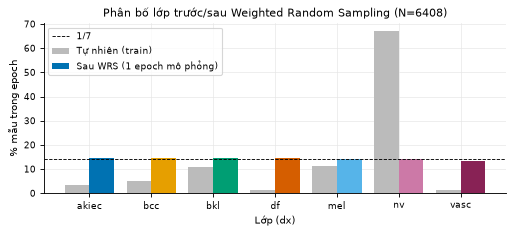

In [19]:
fig, ax = plt.subplots(figsize=(6.5, 3))
x = np.arange(NUM_CLASSES)
ax.bar(x - 0.2, wrs_table["% tự nhiên"], 0.4, label="Tự nhiên (train)", color="#BBBBBB")
ax.bar(x + 0.2, wrs_table["% sau WRS"], 0.4, label="Sau WRS (1 epoch mô phỏng)",
       color=[CLASS_COLORS[c] for c in CLASSES])
ax.axhline(100 / NUM_CLASSES, ls="--", c="k", lw=0.8, label="1/7")
ax.set(xticks=x, xticklabels=CLASSES, ylabel="% mẫu trong epoch", xlabel="Lớp (dx)",
       title=f"Phân bố lớp trước/sau Weighted Random Sampling (N={len(train_df)})")
ax.legend(); plt.tight_layout(); fig.savefig(FIG_DIR / "wrs_distribution.pdf", bbox_inches="tight"); plt.show()

## 7. Pipeline dữ liệu & tối ưu tốc độ (`src/training.py`)

Baseline **không xử lý ảnh**: chỉ `Resize(224×224)` + `Normalize` (ImageNet mean/std), augmentation train = flip ngang/dọc.

**Luồng dữ liệu (giống nhau cho mọi thí nghiệm, chỉ khác `preprocess_fn`):**

`JPEG 600×450 → RGB uint8 → preprocess_fn (thí nghiệm chương 3; baseline: không) → PIL resize 224×224 bilinear → cache uint8 (N,3,224,224)`

- `preprocess_fn` là phép **xác định** nên chạy **một lần** trên ảnh gốc, giống hệt cho train/val/test; kết quả được cache ra
  `outputs/cache/<name>_224.npy` (kèm fingerprint mã nguồn hàm, đổi hàm thì tự tính lại) để lần sau khỏi giải mã JPEG.
- Mỗi batch train: lấy chỉ số từ `WeightedRandomSampler` (generator theo seed) → chuyển batch uint8 lên GPU → **flip ngang/dọc
  ngẫu nhiên (p=0.5, generator theo seed) + normalize trên GPU**. Flip giao hoán với resize nên tương đương làm flip trước resize.
  Không còn DataLoader/PIL/`ToTensor` trong vòng train.

**Tối ưu tốc độ cho GPU 4GB — không đổi cấu hình thí nghiệm** (model, batch 32, lr, wd, 20 epoch, WRS, flip, chọn epoch theo val giữ nguyên). Val/test dự đoán với batch 128 (model ở chế độ eval nên kích thước batch không đổi kết quả, chỉ nhanh hơn):

| Thay đổi | Lợi ích | Đánh đổi |
|---|---|---|
| Cache uint8 trong RAM, flip + normalize trên GPU | Bỏ chi phí `ToTensor`/`Normalize` trên CPU với `num_workers=0` | Không |
| AMP (`autocast` fp16 + `GradScaler`) | Dùng Tensor Core, giảm VRAM | Làm tròn fp16 → kết quả không trùng từng bit với fp32 |
| ~~`channels_last`~~ (đã thử, **không dùng**) | Kỳ vọng nhanh hơn với AMP | Trên RTX 3050 Laptop + torch 2.8 đo được chậm ~4,8x (388 vs 80 ms/step, `outputs/baseline/speed_layout_microbench.csv`) → giữ NCHW |
| `cudnn.benchmark=True`, `deterministic=False` | cuDNN chọn thuật toán nhanh nhất | Hai lần chạy cùng seed có thể lệch nhỏ |

**Tái lập:** cùng seed → cùng khởi tạo `fc`, cùng thứ tự lấy mẫu WRS, cùng mẫu flip; nhưng *không* bảo đảm trùng từng bit
(AMP + cuDNN không tất định). Vì vậy mọi so sánh dựa trên **mean ± std qua 3 seed**; chênh lệch nhỏ hơn std giữa seed được coi
là "không khác biệt rõ". Đánh đổi này được ghi vào `outputs/baseline/config.json` (khoá `speed`).

Thời gian/epoch trước và sau tối ưu đo bằng `scripts/bench_training_speed.py` (cùng dữ liệu, cùng GPU) → `outputs/baseline/speed_benchmark.json`.

> Lưu ý đo đạc: GPU laptop (giới hạn 40 W, nhiệt độ 77–87 °C khi đo) nên thời gian dao động theo nhiệt; pipeline cũ đo được 65 s/epoch ở lần đo đầu và 34 s/epoch ở lần đo lại. Bảng dưới là lần đo lại (cũ và mới chạy liền nhau). Epoch đầu của pipeline mới chậm hơn vì `cudnn.benchmark` dò thuật toán.

In [20]:
bench_f = OUT_DIR / "speed_benchmark.json"
if bench_f.exists():
    bench = json.loads(bench_f.read_text(encoding="utf-8"))
    rows = [{"pipeline": "cũ (PIL + DataLoader, fp32, deterministic)", **bench["old"]["epochs"][0],
             "VRAM đỉnh (MB)": bench["old"]["peak_vram_alloc_mb"]}]
    rows += [{"pipeline": f"mới (src/training.py), epoch {i + 1}", **e, "VRAM đỉnh (MB)": bench["new"]["peak_vram_alloc_mb"]}
             for i, e in enumerate(bench["new"]["epochs"])]
    print(f"GPU: {bench['gpu']} | n_train={bench['n_train']}, n_val={bench['n_val']} | tăng tốc ≈ {bench['speedup_epoch']:.1f}x")
    display(pd.DataFrame(rows).round(1))
else:
    print("Chưa có speed_benchmark.json -> chạy: python -X utf8 scripts/bench_training_speed.py")

Chưa có speed_benchmark.json -> chạy: python -X utf8 scripts/bench_training_speed.py


## 8. Cấu hình baseline (đóng băng)

Mọi thí nghiệm tiền xử lý ảnh sau này giữ nguyên cấu hình này (hằng số `FROZEN_CONFIG` trong `src/training.py`), chỉ thay bước
xử lý ảnh. Chọn epoch tốt nhất theo **macro-F1 trên validation**; test chỉ được đánh giá một lần với checkpoint đó.
`run_experiment` ghi `outputs/baseline/config.json` (cấu hình thí nghiệm + khoá `speed` mô tả AMP/cuDNN).
Bản cấu hình trước khi tách module được giữ ở `outputs/baseline/config_before_refactor.json`; khác biệt duy nhất là phần
cài đặt tốc độ (AMP, cuDNN, pipeline GPU) và tên cột chỉ số (`balanced_acc`, `acc`), cấu hình thí nghiệm không đổi.

In [21]:
SEEDS = list(T.SEEDS)        # [42, 43, 44]
EPOCHS = T.EPOCHS            # 20
RETRAIN = False              # False: seed đã có metrics.json trong outputs/baseline thì đọc lại thay vì train lại
display(pd.Series({**T.FROZEN_CONFIG, "epochs": EPOCHS, "seeds": SEEDS}).to_frame("giá trị"))
pd.Series(T.SPEED_CONFIG).to_frame("cài đặt tốc độ")

,giá trị
model,"resnet18 (torchvision, IMAGENET1K_V1), fc -> 7..."
img_size,224
resize,"PIL Image.resize((224,224), BILINEAR) = transf..."
normalize,ImageNet mean/std
augmentation_train,"flip ngang p=0.5, flip dọc p=0.5 (độc lập, mỗi..."
imbalance,"WeightedRandomSampler, w_i = 1/n_{y_i} (train)..."
loss,CrossEntropyLoss (không class weights)
optimizer,AdamW
lr,0.0001
weight_decay,0.0001


,cài đặt tốc độ
amp,"torch.autocast(cuda, float16) + GradScaler cho..."
channels_last,False
channels_last_note,Mặc định tắt: trên RTX 3050 Laptop + torch 2.8...
cudnn_benchmark,True
cudnn_deterministic,False
data_pipeline,ảnh đã resize cache uint8 trong RAM; flip + no...
eval_batch_size,128
reproducibility_note,"Cùng seed cho cùng thứ tự lấy mẫu WRS, cùng fl..."


## 9. Huấn luyện & đánh giá

Một lệnh `run_experiment("baseline")` cho 3 seed. Mỗi seed lưu `outputs/baseline/seed{s}/`: `history.csv`, `metrics.json`
(val + test, confusion matrix, best_epoch, thời gian, VRAM), `val_preds.csv`, `test_preds.csv` (xác suất 7 lớp, để liên hệ chỉ số
chất lượng ảnh với lỗi CNN bằng dự đoán ngoài mẫu huấn luyện). Checkpoint tốt nhất: `outputs/checkpoints/baseline_seed{s}.pt`.
Tiến độ ghi vào `outputs/baseline_run.log`.

In [22]:
summary_df = run_experiment(
    "baseline", preprocess_fn=None, seeds=SEEDS, epochs=EPOCHS, retrain=RETRAIN,
    log_file="outputs/baseline_run.log",
    description="Baseline: chỉ resize 224 + normalize ImageNet, không xử lý ảnh chương 3",
    extra_config={"missing_age": f"median train = {AGE_MEDIAN} (metadata, không phải đầu vào mô hình)"},
)
results = load_results(OUT_DIR, SEEDS)
summary_df[["seed", "best_epoch", "val_macro_f1", "test_macro_f1", "test_balanced_acc", "test_acc"]].round(4)

[02:16:25] [baseline seed 42] đã có metrics.json -> đọc lại


[02:16:25] [baseline seed 43] đã có metrics.json -> đọc lại


[02:16:25] [baseline seed 44] đã có metrics.json -> đọc lại


,seed,best_epoch,val_macro_f1,test_macro_f1,test_balanced_acc,test_acc
0,42,11,0.7248,0.6784,0.6589,0.8278
1,43,17,0.7213,0.6935,0.6767,0.8338
2,44,15,0.7301,0.7103,0.6976,0.8328


## 10. Kết quả baseline (3 seed)

Số liệu đọc từ `outputs/baseline/seed*/metrics.json` (tổng hợp ở `summary.csv`, `summary_mean_std.csv`);
mean ± std (độ lệch chuẩn mẫu, ddof=1) trên 3 lần chạy.

In [23]:
MAIN = ["macro_f1", "balanced_acc", "acc", "weighted_f1"]
fmt = lambda col: f"{summary_df[col].mean():.4f} ± {summary_df[col].std():.4f}"
main_table = pd.DataFrame({sp: [fmt(f"{sp}_{m}") for m in MAIN] for sp in ("val", "test")}, index=MAIN)
main_table.loc["best_epoch"] = [", ".join(map(str, summary_df["best_epoch"])), ""]
t = pd.DataFrame([r["time"] for r in results], index=SEEDS)
print(f"Thời gian train/seed: {t['train_total_s'].mean() / 60:.1f} ± {t['train_total_s'].std() / 60:.1f} phút | "
      f"epoch TB {t['epoch_mean_s'].mean():.1f}s | VRAM đỉnh {max(r['peak_vram_mb']['allocated'] for r in results):.0f} MB")
main_table

Thời gian train/seed: 3.3 ± 0.1 phút | epoch TB 10.0s | VRAM đỉnh 584 MB


,val,test
macro_f1,0.7254 ± 0.0044,0.6941 ± 0.0160
balanced_acc,0.7236 ± 0.0083,0.6777 ± 0.0194
acc,0.8268 ± 0.0090,0.8315 ± 0.0032
weighted_f1,0.8269 ± 0.0060,0.8290 ± 0.0004
best_epoch,"11, 17, 15",


In [24]:
# Precision / recall / F1 từng lớp trên test (mean ± std, 3 seed)
test_df_counts = test_df["dx"].value_counts()
pc = pd.DataFrame({
    m: [f"{summary_df[f'test_{m}_{c}'].mean():.3f} ± {summary_df[f'test_{m}_{c}'].std():.3f}" for c in CLASSES]
    for m in ["precision", "recall", "f1"]}, index=CLASSES)
pc["n_test"] = test_df_counts.loc[CLASSES].values
pc_num = pd.DataFrame({f"{m}_{s}": [summary_df[f"test_{m}_{c}"].agg(s) for c in CLASSES]
                       for m in ["precision", "recall", "f1"] for s in ["mean", "std"]}, index=CLASSES)
pc_num["n_test"] = pc["n_test"]
pc_num.to_csv(OUT_DIR / "per_class_test.csv")
pc

,precision,recall,f1,n_test
akiec,0.611 ± 0.054,0.510 ± 0.162,0.551 ± 0.122,66
bcc,0.690 ± 0.049,0.828 ± 0.072,0.751 ± 0.034,103
bkl,0.667 ± 0.033,0.729 ± 0.051,0.695 ± 0.012,220
df,0.870 ± 0.114,0.522 ± 0.075,0.647 ± 0.053,23
mel,0.588 ± 0.042,0.518 ± 0.090,0.546 ± 0.036,222
nv,0.921 ± 0.009,0.924 ± 0.009,0.922 ± 0.002,1341
vasc,0.786 ± 0.083,0.713 ± 0.080,0.747 ± 0.075,29


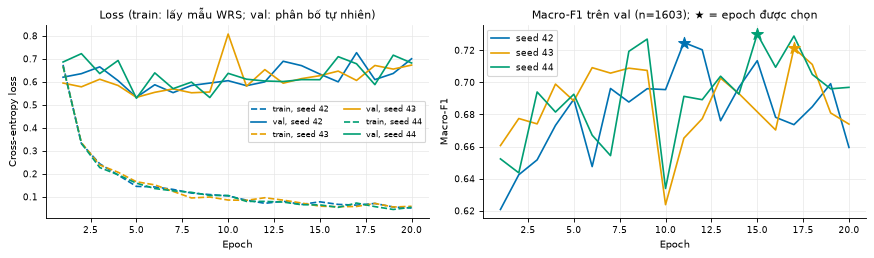

In [25]:
# Đường học: train/val loss và val macro-F1 theo epoch (chọn epoch bằng val)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
seed_colors = dict(zip(SEEDS, ["#0072B2", "#E69F00", "#009E73"]))
for s in SEEDS:
    h = pd.read_csv(OUT_DIR / f"seed{s}" / "history.csv")
    axes[0].plot(h.epoch, h.train_loss, c=seed_colors[s], ls="--", label=f"train, seed {s}")
    axes[0].plot(h.epoch, h.val_loss, c=seed_colors[s], label=f"val, seed {s}")
    axes[1].plot(h.epoch, h.val_macro_f1, c=seed_colors[s], label=f"seed {s}")
    be = h.val_macro_f1.idxmax()
    axes[1].scatter(h.epoch[be], h.val_macro_f1[be], color=seed_colors[s], marker="*", s=120, zorder=3)
axes[0].set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Loss (train: lấy mẫu WRS; val: phân bố tự nhiên)")
axes[1].set(xlabel="Epoch", ylabel="Macro-F1", title=f"Macro-F1 trên val (n={len(val_df)}); ★ = epoch được chọn")
axes[0].legend(ncol=2, fontsize=7); axes[1].legend()
plt.tight_layout(); fig.savefig(FIG_DIR / "learning_curves.pdf", bbox_inches="tight")
fig.savefig(FIG_DIR / "learning_curves.png", bbox_inches="tight", dpi=300); plt.show()

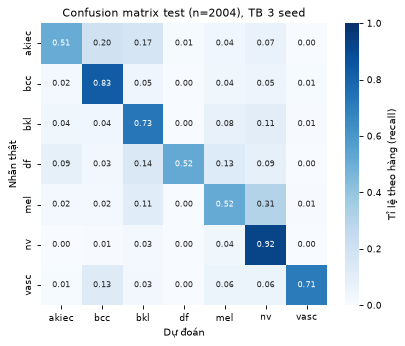

,thật,dự đoán,tỉ lệ hàng mean,tỉ lệ hàng std,số ảnh TB,n lớp thật
28,mel,nv,0.311,0.072,69.000,222
0,akiec,bcc,0.202,0.103,13.333,66
1,akiec,bkl,0.172,0.070,11.333,66
20,df,bkl,0.145,0.050,3.333,23
21,df,mel,0.130,0.115,3.000,23
37,vasc,bcc,0.126,0.020,3.667,29
26,mel,bkl,0.114,0.023,25.333,222
16,bkl,nv,0.109,0.025,24.000,220


In [26]:
# Confusion matrix trên test: chuẩn hoá theo hàng (= recall), trung bình 3 seed
cms = np.array([r["test_confusion_matrix"] for r in results], dtype=float)
cm_norm = (cms / cms.sum(2, keepdims=True)).mean(0)
fig, ax = plt.subplots(figsize=(5.2, 4.4))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, xticklabels=CLASSES, yticklabels=CLASSES,
            cbar_kws={"label": "Tỉ lệ theo hàng (recall)"}, ax=ax, annot_kws={"size": 7})
ax.set(xlabel="Dự đoán", ylabel="Nhãn thật",
       title=f"Confusion matrix test (n={len(test_df)}), TB {len(SEEDS)} seed")
plt.tight_layout(); fig.savefig(FIG_DIR / "confusion_matrix_test.pdf", bbox_inches="tight")
fig.savefig(FIG_DIR / "confusion_matrix_test.png", bbox_inches="tight", dpi=300); plt.show()

# Các cặp (thật -> dự đoán) bị nhầm nhiều nhất: tỉ lệ theo hàng (mean ± std 3 seed) và số ảnh TB
cm_rows = cms / cms.sum(2, keepdims=True)
pairs = [{"thật": CLASSES[i], "dự đoán": CLASSES[j], "tỉ lệ hàng mean": cm_rows[:, i, j].mean(),
          "tỉ lệ hàng std": cm_rows[:, i, j].std(ddof=1), "số ảnh TB": cms[:, i, j].mean(),
          "n lớp thật": int(cms[0, i].sum())}
         for i in range(len(CLASSES)) for j in range(len(CLASSES)) if i != j]
confused = pd.DataFrame(pairs).sort_values("tỉ lệ hàng mean", ascending=False)
confused.to_csv(OUT_DIR / "confused_pairs_test.csv", index=False)
confused.head(8).round(3)

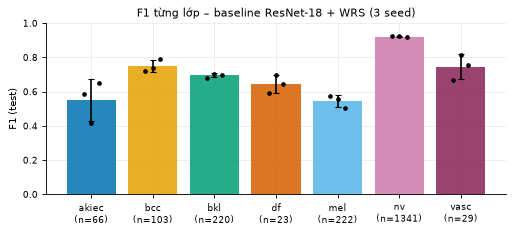

In [27]:
# F1 từng lớp trên test: cột = mean, thanh = std, điểm = từng seed
fig, ax = plt.subplots(figsize=(6.5, 3))
x = np.arange(len(CLASSES))
means = [summary_df[f"test_f1_{c}"].mean() for c in CLASSES]
stds = [summary_df[f"test_f1_{c}"].std() for c in CLASSES]
ax.bar(x, means, yerr=stds, capsize=3, color=[CLASS_COLORS[c] for c in CLASSES], alpha=0.85)
for i, c in enumerate(CLASSES):
    ax.scatter(np.full(len(summary_df), i) + np.linspace(-0.12, 0.12, len(summary_df)), summary_df[f"test_f1_{c}"],
               c="k", s=10, zorder=3)
ax.set(xticks=x, xticklabels=[f"{c}\n(n={n})" for c, n in zip(CLASSES, pc["n_test"])], ylim=(0, 1),
       ylabel="F1 (test)", title=f"F1 từng lớp – baseline ResNet-18 + WRS ({len(SEEDS)} seed)")
plt.tight_layout(); fig.savefig(FIG_DIR / "per_class_f1_test.pdf", bbox_inches="tight")
fig.savefig(FIG_DIR / "per_class_f1_test.png", bbox_inches="tight", dpi=300); plt.show()

## 11. Nhận xét

Mọi con số dưới đây đọc trực tiếp từ lượt chạy thống nhất trên NVIDIA L40S (`outputs/baseline/summary.csv`, `per_class_test.csv`, `outputs/errors/confused_pairs_baseline_test.csv`, `seed*/history.csv`); mean ± std (`ddof=1`) trên **3 seed (42, 43, 44)**, `test` $n = 2\,004$, `val` $n = 1\,603$.

**Chỉ số tổng hợp (Bảng mục 10)**

| Chỉ số | Val | Test |
|---|---|---|
| Macro-F1 (chính) | 0.7254 ± 0.0044 | **0.6941 ± 0.0160** |
| Balanced accuracy | 0.7236 ± 0.0083 | 0.6777 ± 0.0194 |
| Accuracy | 0.8268 ± 0.0090 | 0.8315 ± 0.0032 |
| Weighted-F1 | 0.8269 ± 0.0060 | 0.8290 ± 0.0004 |

- Test macro-F1 theo từng seed (42 / 43 / 44): `0.6784 / 0.6935 / 0.7103`; độ lệch chuẩn giữa các seed là `0.0160`. **Ngưỡng tham chiếu cho mục 2.5:** chênh lệch $|\Delta|$ nhỏ hơn std của baseline (hoặc CI95 bootstrap cụm lesion chứa 0 / dấu không đồng nhất 3/3 seed) được kết luận là *"không khác biệt rõ"*.
- Epoch được chọn theo `val` macro-F1: `11, 17, 15`. Val macro-F1 cao hơn test khoảng `0.031` một phần do thiên lệch chọn checkpoint tốt nhất trên `val`.
- Accuracy ($pprox 0.832$) cao hơn hẳn macro-F1 ($pprox 0.694$) vì lớp `nv` chiếm 1 341/2 004 ảnh test; đây là lý do dùng macro-F1 làm độ đo chính.

**Theo lớp trên tập Test (`per_class_f1_test.pdf`)**

| Lớp | n test | Recall | F1 |
|---|---:|---|---|
| `akiec` | 66 | 0.510 ± 0.162 | 0.551 ± 0.122 |
| `bcc` | 103 | 0.828 ± 0.072 | 0.751 ± 0.034 |
| `bkl` | 220 | 0.729 ± 0.051 | 0.695 ± 0.012 |
| `df` | 23 | 0.522 ± 0.075 | 0.647 ± 0.053 |
| `mel` | 222 | 0.518 ± 0.090 | 0.546 ± 0.036 |
| `nv` | 1341 | 0.924 ± 0.009 | 0.922 ± 0.002 |
| `vasc` | 29 | 0.713 ± 0.080 | 0.747 ± 0.075 |

**5 cặp lớp bị nhầm nhiều nhất trên Test (`confusion_baseline_test.pdf`)**

| Thật → Dự đoán | Tỉ lệ hàng | Số ảnh TB / n lớp thật |
|---|---|---|
| `mel` → `nv` | 0.311 ± 0.072 | 69.0 / 222 |
| `akiec` → `bcc` | 0.202 ± 0.103 | 13.3 / 66 |
| `akiec` → `bkl` | 0.172 ± 0.070 | 11.3 / 66 |
| `df` → `bkl` | 0.145 ± 0.050 | 3.3 / 23 |
| `df` → `mel` | 0.130 ± 0.115 | 3.0 / 23 |

- Liên hệ định lượng giữa dự đoán ngoài mẫu của baseline với 6 cờ chất lượng ảnh đã được đối chiếu đầy đủ ở mục 5 của `2.2_eda_chat_luong_anh.ipynb` và mục `2.8.4` (`outputs/errors/subgroup_error_class_matched.csv`).